# E-commerce Sales & Customer Analysis
**Goal:** Understand revenue drivers, profitability, seasonality and customer value for an online retailer (Jan 2024 – Dec 2025), and recommend where to focus marketing and inventory.

**Business questions**
1. How is revenue trending and how strong is festive seasonality?
2. Which categories drive revenue vs. profit?
3. Which channels / payment methods / states matter most?
4. Who are our best customers (RFM) and how well do we retain new ones (cohorts)?

*Data is synthetic and generated by `generate_data.py` — see README.*

In [122]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import os
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"]=110
cust = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])
prod = pd.read_csv("data/products.csv")
orders = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
items = pd.read_csv("data/order_items.csv")
for n,d in [("customers",cust),("products",prod),("orders",orders),("items",items)]:
    print(n, d.shape)

customers (3000, 4)
products (150, 5)
orders (21517, 6)
items (34428, 4)


In [123]:
datasets = {
    "customers": cust,
    "products": prod,
    "orders": orders,
    "order_items": items
}

for name, df in datasets.items():
    print(f"\n{'=' * 40}")
    print(f"DATASET: {name}")
    print(f"Shape: {df.shape}")
    print("\nColumn names and data types:")
    print(df.dtypes)
    print("\nFirst 5 rows:")
    display(df.head())


DATASET: customers
Shape: (3000, 4)

Column names and data types:
customer_id               str
state                     str
signup_date    datetime64[us]
segment                   str
dtype: object

First 5 rows:


,customer_id,state,signup_date,segment
0,C00001,Gujarat,2024-03-28,Regular
1,C00002,Delhi,2024-08-28,Regular
2,C00003,Telangana,2024-04-12,Regular
3,C00004,NaN,2024-03-09,Regular
4,C00005,Maharashtra,2023-12-08,Regular



DATASET: products
Shape: (150, 5)

Column names and data types:
product_id          str
product_name        str
category            str
unit_price      float64
unit_cost       float64
dtype: object

First 5 rows:


,product_id,product_name,category,unit_price,unit_cost
0,P0001,Electronics Item 1,Electronics,13785.0,12131.0
1,P0002,Electronics Item 2,Electronics,18979.0,16702.0
2,P0003,Electronics Item 3,Electronics,6735.0,5927.0
3,P0004,Electronics Item 4,Electronics,12485.0,10987.0
4,P0005,Electronics Item 5,Electronics,14482.0,12744.0



DATASET: orders
Shape: (21517, 6)

Column names and data types:
order_id                     str
customer_id                  str
order_date        datetime64[us]
channel                      str
payment_method               str
status                       str
dtype: object

First 5 rows:


,order_id,customer_id,order_date,channel,payment_method,status
0,O000001,C01910,2024-01-01,Referral,UPI,Delivered
1,O000007,C01925,2024-01-01,Paid Search,Wallet,Cancelled
2,O000008,C02610,2024-01-01,Organic,Credit Card,Delivered
3,O000009,C02351,2024-01-01,Organic,Credit Card,Delivered
4,O000011,C01896,2024-01-01,Email,Debit Card,Delivered



DATASET: order_items
Shape: (34428, 4)

Column names and data types:
order_id          str
product_id        str
quantity        int64
discount_pct    int64
dtype: object

First 5 rows:


,order_id,product_id,quantity,discount_pct
0,O000001,P0038,1,0
1,O000007,P0128,1,0
2,O000008,P0020,1,0
3,O000008,P0019,1,0
4,O000009,P0043,3,10


In [124]:
for name, data in datasets.items():
    print(f"\n--- {name.upper()} ---")
    print(data.isnull().sum())


--- CUSTOMERS ---
customer_id     0
state          60
signup_date     0
segment         0
dtype: int64

--- PRODUCTS ---
product_id      0
product_name    0
category        0
unit_price      0
unit_cost       0
dtype: int64

--- ORDERS ---
order_id          0
customer_id       0
order_date        0
channel           0
payment_method    0
status            0
dtype: int64

--- ORDER_ITEMS ---
order_id        0
product_id      0
quantity        0
discount_pct    0
dtype: int64


## 1. Data cleaning

In [125]:
# fill the missing state values with unknown
cust["state"]=cust["state"].fillna("Unknown")


In [126]:
print(orders.payment_method.value_counts())   # inconsistent casing
# here we see casing issue hence python is reading it cause seperate method 

payment_method
UPI            8435
Credit Card    4376
COD            3865
Debit Card     3281
Wallet         1520
upi              20
debit card       10
wallet            4
cod               4
credit card       2
Name: count, dtype: int64


In [127]:
# replaced the case values with correct ones
orders["payment_method"] = orders.payment_method.str.title().replace({"Upi":"UPI","Cod":"COD"})


In [128]:

orders.payment_method.value_counts()

payment_method
UPI            8455
Credit Card    4378
COD            3869
Debit Card     3291
Wallet         1524
Name: count, dtype: int64

In [129]:
display(
    items[items["order_id"] == "O000513"]
)

,order_id,product_id,quantity,discount_pct
434,O000513,P0110,2,0
435,O000513,P0030,1,0
436,O000513,P0141,1,10
437,O000513,P0030,1,0


DATA QUALITY CHECK

In [130]:
# DATA QUALITY AUDIT

datasets = {
    "Customers": cust,
    "Products": prod,
    "Orders": orders,
    "Order Items": items
}

for name, data in datasets.items():
    print(f"\n{'=' * 45}")
    print(f"{name.upper()}")

    print("Total rows:", len(data))
    print("Completely duplicated rows:", data.duplicated().sum())
    print("Missing values:", data.isnull().sum().sum())

# Check whether foreign keys match across tables
print("\n" + "=" * 45)
print("RELATIONSHIP CHECKS")

print(
    "Orders with unknown customers:",
    (~orders["customer_id"].isin(cust["customer_id"])).sum()
)

print(
    "Order items with unknown orders:",
    (~items["order_id"].isin(orders["order_id"])).sum()
)

print(
    "Order items with unknown products:",
    (~items["product_id"].isin(prod["product_id"])).sum()
)

# Check numerical values
print("\n" + "=" * 45)
print("NUMERICAL VALIDATION")

print("Products with price <= 0:", (prod["unit_price"] <= 0).sum())
print("Products with cost < 0:", (prod["unit_cost"] < 0).sum())
print("Order items with quantity <= 0:", (items["quantity"] <= 0).sum())
print("Order items with discount outside 0–100:",
      ((items["discount_pct"] < 0) | (items["discount_pct"] > 100)).sum())


CUSTOMERS
Total rows: 3000
Completely duplicated rows: 0
Missing values: 0

PRODUCTS
Total rows: 150
Completely duplicated rows: 0
Missing values: 0

ORDERS
Total rows: 21517
Completely duplicated rows: 0
Missing values: 0

ORDER ITEMS
Total rows: 34428
Completely duplicated rows: 35
Missing values: 0

RELATIONSHIP CHECKS
Orders with unknown customers: 0
Order items with unknown orders: 0
Order items with unknown products: 0

NUMERICAL VALIDATION
Products with price <= 0: 0
Products with cost < 0: 0
Order items with quantity <= 0: 0
Order items with discount outside 0–100: 0


In [131]:
# Preserve the original data
items_clean = items.copy()

# Remove exact duplicate rows
items_clean = items_clean.drop_duplicates()

print("Original rows:", len(items))
print("Rows after cleaning:", len(items_clean))
print("Rows removed:", len(items) - len(items_clean))
print("Remaining duplicate rows:", items_clean.duplicated().sum())

Original rows: 34428
Rows after cleaning: 34393
Rows removed: 35
Remaining duplicate rows: 0


## 2. Build the analysis table
Revenue = quantity × unit price × (1 − discount). Only **Delivered** orders count as realised revenue.

In [132]:
df = (
    items_clean
    .merge(orders, on="order_id")
    .merge(prod, on="product_id")
    .merge(cust, on="customer_id")
)
# joins all the files

In [133]:

df["revenue"] = df.quantity*df.unit_price*(1-df.discount_pct/100)
df["cost"] = df.quantity*df.unit_cost
df["profit"] = df.revenue-df.cost
df["month"] = df.order_date.dt.to_period("M").dt.to_timestamp()
d = df[df.status=="Delivered"].copy()
total_orders = d.order_id.nunique()

In [134]:
kpi = pd.Series({
 "Revenue": d.revenue.sum(), "Profit": d.profit.sum(), "Margin %": d.profit.sum()/d.revenue.sum()*100,
 "Orders": total_orders, "Avg order value": d.revenue.sum()/total_orders,
 "Customers": d.customer_id.nunique(), "Return rate %": (orders.status=="Returned").mean()*100,
 "Cancel rate %": (orders.status=="Cancelled").mean()*100})
kpi.round(1)

Revenue            152201060.3
Profit              23890904.3
Margin %                  15.7
Orders                 18893.0
Avg order value         8055.9
Customers               2863.0
Return rate %              7.0
Cancel rate %              5.2
dtype: float64

In [135]:
print("Original order items:", len(items))
print("Cleaned order items:", len(items_clean))
print("Rows in analysis table:", len(df))

print("\nUnique orders in original data:", orders["order_id"].nunique())
print("Unique orders in analysis table:", df["order_id"].nunique())

print("\nCustomers in customer table:", cust["customer_id"].nunique())
print("Customers in analysis table:", df["customer_id"].nunique())

Original order items: 34428
Cleaned order items: 34393
Rows in analysis table: 34393

Unique orders in original data: 21517
Unique orders in analysis table: 21517

Customers in customer table: 3000
Customers in analysis table: 2899


In [136]:
customers_without_orders = cust[
    ~cust["customer_id"].isin(orders["customer_id"])
]

print("Customers without any orders:", len(customers_without_orders))

display(customers_without_orders.head(10))

Customers without any orders: 101


,customer_id,state,signup_date,segment
69,C00070,Delhi,2024-12-20,Regular
80,C00081,West Bengal,2024-10-17,Regular
84,C00085,Unknown,2024-05-06,Regular
106,C00107,Delhi,2023-01-19,Premium
152,C00153,Maharashtra,2024-04-25,Regular
168,C00169,Karnataka,2024-08-21,Premium
190,C00191,Uttar Pradesh,2024-10-20,Regular
278,C00279,Telangana,2023-01-29,Regular
341,C00342,Uttar Pradesh,2024-12-21,Regular
380,C00381,Tamil Nadu,2023-08-01,Regular


In [137]:
# Compare the business impact of removing exact duplicate rows

def compare_metrics(order_items, label):
    analysis = (
        order_items
        .merge(orders, on="order_id")
        .merge(prod, on="product_id")
    )

    delivered = analysis[analysis["status"] == "Delivered"].copy()

    delivered["revenue"] = (
        delivered["quantity"]
        * delivered["unit_price"]
        * (1 - delivered["discount_pct"] / 100)
    )

    delivered["cost"] = (
        delivered["quantity"] * delivered["unit_cost"]
    )

    delivered["profit"] = delivered["revenue"] - delivered["cost"]

    print(f"\n{label}")
    print("Revenue:", round(delivered["revenue"].sum(), 2))
    print("Profit:", round(delivered["profit"].sum(), 2))
    print("Delivered order count:", delivered["order_id"].nunique())


compare_metrics(items, "BEFORE CLEANING")
compare_metrics(items_clean, "AFTER CLEANING")


BEFORE CLEANING
Revenue: 152323671.0
Profit: 23914281.0
Delivered order count: 18893

AFTER CLEANING
Revenue: 152201060.3
Profit: 23890904.3
Delivered order count: 18893


### Duplicate Handling

The original `order_items` dataset contained 34,428 rows, including 35 exact duplicate rows. Removing these rows produced a cleaned dataset of 34,393 rows.

A comparison of business metrics before and after cleaning showed that removing the duplicates reduced revenue by ₹12,206.80 and profit by ₹23,376.70, while the number of delivered orders remained unchanged at 18,893.

The cleaned dataset, `items_clean`, is used for subsequent analysis. The original dataset, `items`, is preserved for traceability. The duplicates are treated as accidental duplicates pending confirmation of their origin.


## 3. Revenue trend & seasonality

/var/folders/z8/v0b5gqfs71dbk3tt6q7vdmh80000gn/T/ipykernel_14541/614687472.py:4: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/Users/soumenmandal/Desktop/claud_projects_dataanalust/Ecommerce_Sales_Analysis/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


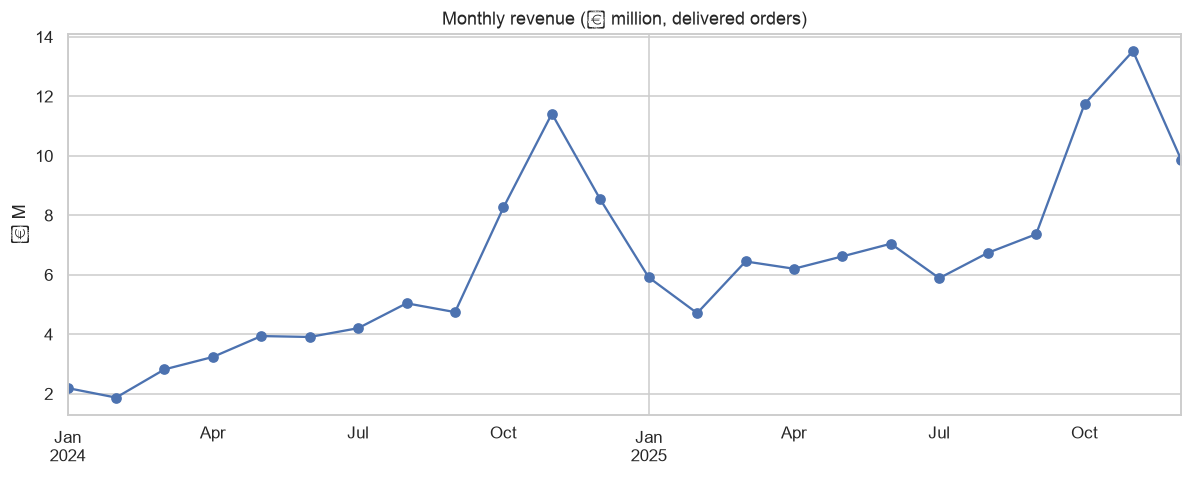

YoY growth by month (%): [170. 152. 129.  92.  68.  80.  40.  34.  55.  42.  18.  15.]
Oct+Nov share of total revenue: 29.5% (2 of 24 months = 8.3% if flat)


In [138]:
m = d.groupby("month").revenue.sum()/1e6
fig,ax = plt.subplots(figsize=(11,4.5))
m.plot(ax=ax, marker="o"); ax.set_title("Monthly revenue (₹ million, delivered orders)"); ax.set_ylabel("₹ M"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
yoy = (m["2025"].values/m["2024"].values-1)*100
print("YoY growth by month (%):", np.round(yoy,0))
festive = d[d.order_date.dt.month.isin([10,11])].revenue.sum()/d.revenue.sum()*100
print(f"Oct+Nov share of total revenue: {festive:.1f}% (2 of 24 months = 8.3% if flat)")

## 4. Category performance — revenue vs margin

/var/folders/z8/v0b5gqfs71dbk3tt6q7vdmh80000gn/T/ipykernel_14541/3054883379.py:7: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/Users/soumenmandal/Desktop/claud_projects_dataanalust/Ecommerce_Sales_Analysis/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


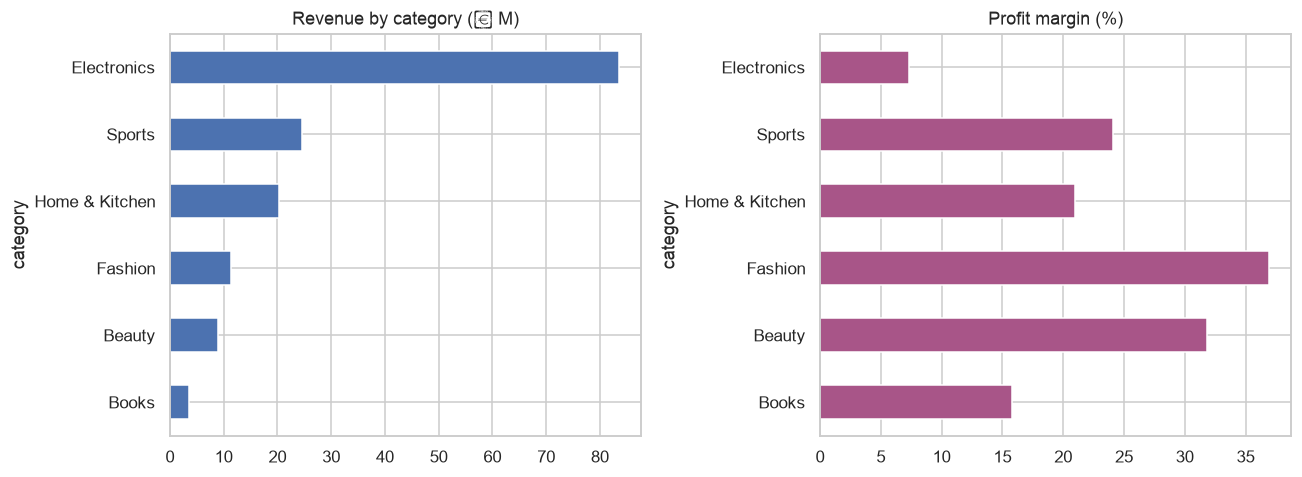

,revenue,profit,margin_%
category,,,
Electronics,83522854.2,6131215.2,7.3
Sports,24528628.2,5920032.2,24.1
Home & Kitchen,20364479.0,4277020.0,21.0
Fashion,11276819.3,4163646.3,36.9
Beauty,8875966.2,2825281.2,31.8
Books,3632313.2,573709.2,15.8


In [139]:
cat = d.groupby("category").agg(revenue=("revenue","sum"), profit=("profit","sum"))
cat["margin_%"] = cat.profit/cat.revenue*100
cat = cat.sort_values("revenue", ascending=False)
fig,ax = plt.subplots(1,2, figsize=(12,4.5))
(cat.revenue/1e6).plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Revenue by category (₹ M)"); ax[0].invert_yaxis()
cat["margin_%"].plot.barh(ax=ax[1], color="#A85588"); ax[1].set_title("Profit margin (%)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()
cat.round(1)

## 5. Channels, payment methods and states

/var/folders/z8/v0b5gqfs71dbk3tt6q7vdmh80000gn/T/ipykernel_14541/1242655206.py:4: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
/Users/soumenmandal/Desktop/claud_projects_dataanalust/Ecommerce_Sales_Analysis/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


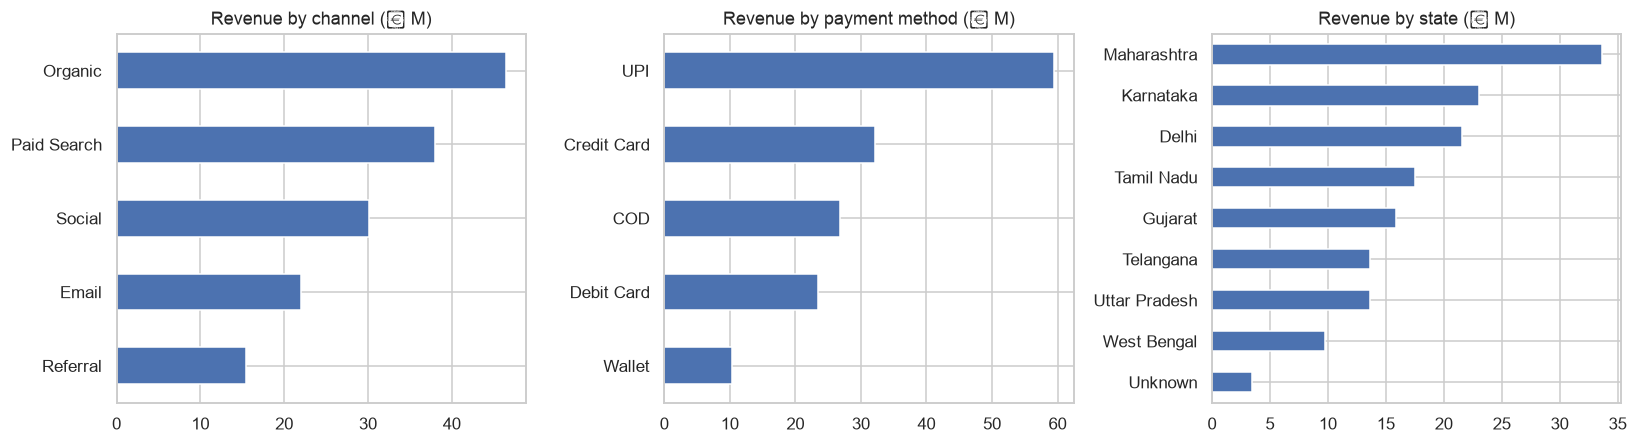

Non-delivery rate by payment method (%) — roughly equal across methods:
 payment_method
COD            12.8
Credit Card    12.1
Debit Card     12.1
UPI            12.1
Wallet         11.8
Name: status, dtype: float64


In [140]:
fig,ax = plt.subplots(1,3, figsize=(15,4.2))
for a,(col,t) in zip(ax,[("channel","Revenue by channel"),("payment_method","Revenue by payment method"),("state","Revenue by state")]):
    (d.groupby(col).revenue.sum().sort_values()/1e6).plot.barh(ax=a); a.set_title(t+" (₹ M)"); a.set_ylabel("")
plt.tight_layout(); plt.show()
cod = orders.groupby("payment_method").status.apply(lambda s:(s!="Delivered").mean()*100).round(1)
print("Non-delivery rate by payment method (%) — roughly equal across methods:\n", cod)

## 6. Customer segmentation — RFM
Score recency, frequency and monetary value 1–5 (quintiles) and label segments.

In [141]:
snap = d.order_date.max()+pd.Timedelta(days=1)
rfm = d.groupby("customer_id").agg(recency=("order_date",lambda s:(snap-s.max()).days),
        frequency=("order_id","nunique"), monetary=("revenue","sum"))
rfm["R"]=pd.qcut(rfm.recency.rank(method="first"),5,labels=[5,4,3,2,1]).astype(int)
rfm["F"]=pd.qcut(rfm.frequency.rank(method="first"),5,labels=[1,2,3,4,5]).astype(int)
rfm["M"]=pd.qcut(rfm.monetary.rank(method="first"),5,labels=[1,2,3,4,5]).astype(int)
def seg(r):
    if r.R>=4 and r.F>=4: return "Champions"
    if r.R>=3 and r.F>=3: return "Loyal"
    if r.R>=4 and r.F<=2: return "New / Promising"
    if r.R<=2 and r.F>=3: return "At risk"
    if r.R<=2 and r.F<=2: return "Lost"
    return "Needs attention"
rfm["segment"]=rfm.apply(seg,axis=1)
s = rfm.groupby("segment").agg(customers=("monetary","size"), revenue=("monetary","sum"), avg_orders=("frequency","mean"))
s["revenue_share_%"]=s.revenue/s.revenue.sum()*100
s["customer_share_%"]=s.customers/s.customers.sum()*100
s = s.sort_values("revenue", ascending=False)
s.round(1)

,customers,revenue,avg_orders,revenue_share_%,customer_share_%
segment,,,,,
Champions,732,79066270.0,13.4,51.9,25.6
Loyal,589,32684751.8,7.0,21.5,20.6
At risk,397,20307121.5,6.3,13.3,13.9
Lost,748,12202927.2,2.0,8.0,26.1
New / Promising,205,4346680.2,2.5,2.9,7.2
Needs attention,192,3593309.6,2.5,2.4,6.7


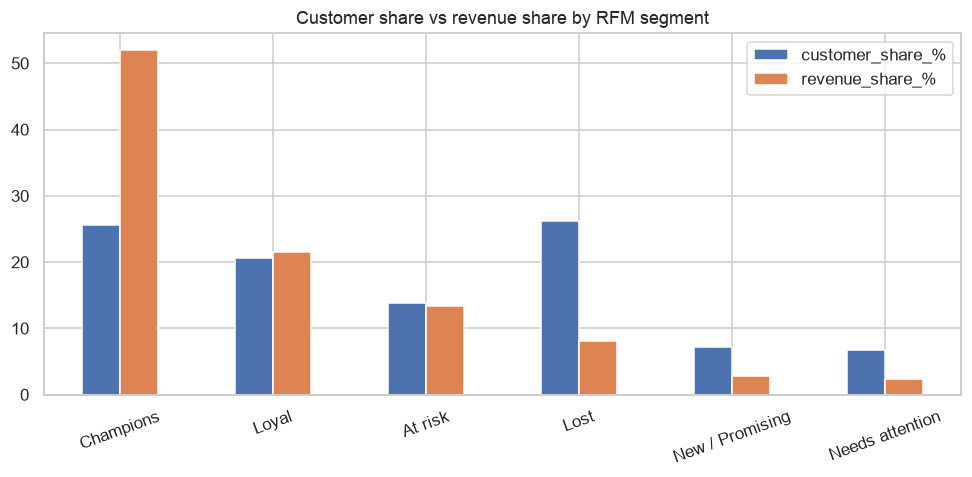

Top 20% of customers generate 53.8% of revenue


In [142]:
fig,ax = plt.subplots(figsize=(9,4.5))
s[["customer_share_%","revenue_share_%"]].plot.bar(ax=ax); ax.set_title("Customer share vs revenue share by RFM segment"); ax.set_xlabel("")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
top20 = rfm.sort_values("monetary",ascending=False).head(int(len(rfm)*.2)).monetary.sum()/rfm.monetary.sum()*100
print(f"Top 20% of customers generate {top20:.1f}% of revenue")

## 7. Cohort retention
Share of each signup-month cohort that orders again in the months after their first order.

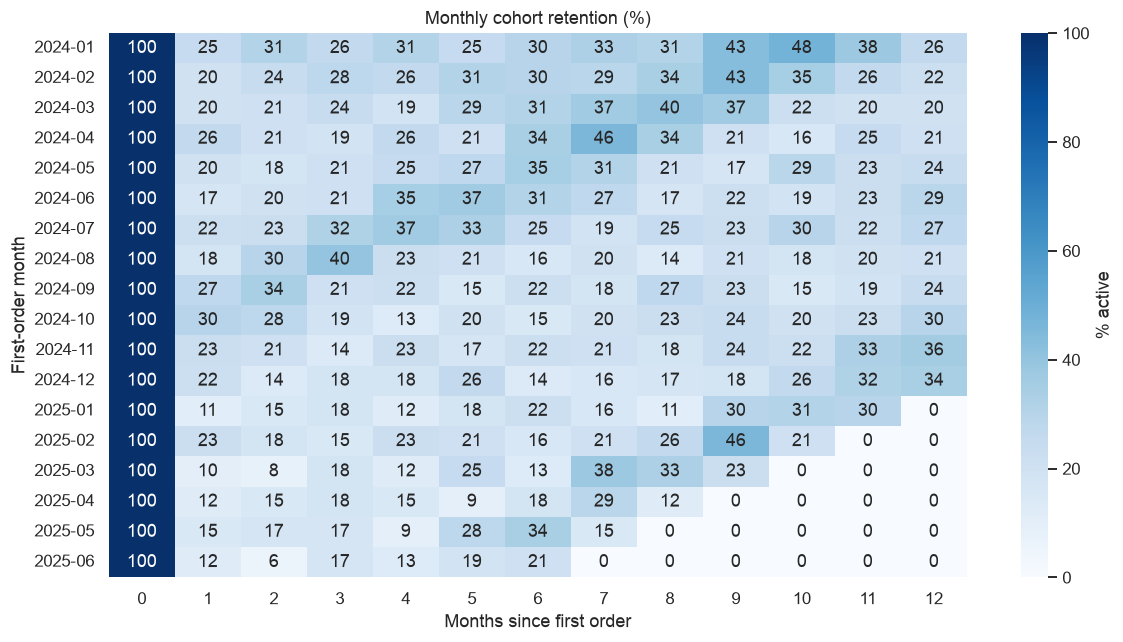

In [143]:
o = orders[orders.status=="Delivered"][["customer_id","order_date"]].copy()
o["order_m"]=o.order_date.dt.to_period("M")
first = o.groupby("customer_id").order_m.min().rename("cohort")
o = o.join(first, on="customer_id"); o["age"]=(o.order_m-o.cohort).apply(lambda x:x.n)
coh = o.groupby(["cohort","age"]).customer_id.nunique().unstack(fill_value=0)
ret = coh.div(coh[0],axis=0)*100
ret = ret[ret.index<="2025-06"].iloc[:, :13]
plt.figure(figsize=(11,6)); sns.heatmap(ret.round(0), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label":"% active"})
plt.title("Monthly cohort retention (%)"); plt.ylabel("First-order month"); plt.xlabel("Months since first order")
plt.tight_layout(); plt.show()

## 8. Export summary tables for Excel / Power BI

In [144]:
os.makedirs("outputs", exist_ok=True)
d[["order_id","order_date","month","customer_id","state","segment","channel","payment_method","product_id","category","quantity","discount_pct","revenue","profit"]].to_csv("outputs/fact_sales_clean.csv", index=False)
rfm.reset_index().to_csv("outputs/rfm_segments.csv", index=False)
with pd.ExcelWriter("outputs/ecommerce_summary.xlsx") as xw:
    kpi.round(2).to_frame("value").to_excel(xw, sheet_name="KPIs")
    m.rename("revenue_M").to_frame().to_excel(xw, sheet_name="Monthly")
    cat.round(2).to_excel(xw, sheet_name="Category"); s.round(2).to_excel(xw, sheet_name="RFM")
print("saved")

saved


## 9. Key findings & recommendations
See the README for the numbers from this run. In short:
- **Seasonality:** Oct–Nov carry a disproportionate share of revenue → plan inventory, ad budget and logistics capacity ahead of the festive peak.
- **Revenue ≠ profit:** Electronics leads on revenue but has the thinnest margin; Fashion / Beauty drive profit → bundle high-margin items with electronics.
- **Customer concentration:** a small group of Champions / Loyal customers contributes a large revenue share → loyalty programme + win-back for *At risk*.
- **Payment method:** non-delivery (returns + cancellations) is ~11–13% across all methods, so COD is *not* a special risk here — no policy change needed. Worth re-checking with real data.